# Phân tích và phân cụm khách hàng trung tâm thương mại

Notebook này gộp EDA và phân cụm thành một luồng: kiểm tra dữ liệu → khám phá biểu đồ → tiền xử lý và Feature Scaling → chọn K → đánh giá → phân tích cụm → dự đoán khách hàng mới.

Mô hình chính đọc cấu hình cuối từ config.yaml: không dùng giới tính, StandardScaler, K=6. Phần cuối giữ cấu hình so sánh có giới tính, MinMaxScaler, K=2 từ notebook cũ. Không so sánh trực tiếp metric giữa hai không gian đặc trưng/thang đo khác nhau.

Mỗi hình được tạo từ dữ liệu dưới dạng biểu đồ độc lập, lưu thành một file PNG riêng và có nhận xét/đánh giá ngay bên dưới. Đầu ra notebook được lưu riêng dưới notebooks/ để không ghi đè model chuẩn của pipeline.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw" / "Mall_Customers.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data" / "raw" / "Mall_Customers.csv").exists():
    raise FileNotFoundError("Không tìm thấy data/raw/Mall_Customers.csv")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import get_config
from src.feature_processing import clean_records, prepare_feature_frame
from src.models.kmeans import KMeans

FIGURE_DIR = (
    PROJECT_ROOT / "notebooks" / "reports" / "figures"
    / "customer_segmentation" / "unified"
)
RESULT_DIR = PROJECT_ROOT / "notebooks" / "progress_results" / "unified_notebook"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5.5)

def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Đã lưu biểu đồ riêng: {path.relative_to(PROJECT_ROOT)}")

## 1. Nạp dữ liệu và kiểm tra chất lượng

CustomerID là mã định danh, không phải đặc trưng khoảng cách. Dữ liệu thiếu/trùng được xử lý theo cấu hình khi chuẩn bị feature; các giá trị ngoài ngưỡng IQR được thống kê riêng, không tự động xóa.

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Mall_Customers.csv"
raw_df = pd.read_csv(DATA_PATH)

print(f"Kích thước dữ liệu: {raw_df.shape[0]} dòng × {raw_df.shape[1]} cột")
display(raw_df.head())

Kích thước dữ liệu: 200 dòng × 5 cột


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
quality = pd.DataFrame({
    "Missing": raw_df.isna().sum(),
    "Unique": raw_df.nunique(dropna=False),
})
print(f"Số dòng trùng toàn bộ: {int(raw_df.duplicated().sum())}")
display(quality)
display(raw_df.describe(include="all").T)

Số dòng trùng toàn bộ: 0


,Missing,Unique
CustomerID,0,200
Gender,0,2
Age,0,51
Annual Income (k$),0,64
Spending Score (1-100),0,84


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


In [4]:
numeric_columns = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
numeric_df = raw_df[numeric_columns].apply(pd.to_numeric, errors="coerce")
outlier_rows = []
for column in numeric_columns:
    q1 = numeric_df[column].quantile(0.25)
    q3 = numeric_df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (numeric_df[column] < lower) | (numeric_df[column] > upper)
    outlier_rows.append({
        "Feature": column,
        "Q1": q1,
        "Q3": q3,
        "Lower bound": lower,
        "Upper bound": upper,
        "Outlier count": int(mask.sum()),
        "Outlier %": 100 * float(mask.mean()),
    })
outlier_summary = pd.DataFrame(outlier_rows).round(2)
display(outlier_summary)

,Feature,Q1,Q3,Lower bound,Upper bound,Outlier count,Outlier %
0,Age,28.75,49.0,-1.62,79.38,0,0.0
1,Annual Income (k$),41.50,78.0,-13.25,132.75,2,1.0
2,Spending Score (1-100),34.75,73.0,-22.62,130.38,0,0.0


## 2. EDA: biểu đồ độc lập

Histogram mô tả tần suất; boxplot cho thấy trung vị, khoảng tứ phân vị và điểm ngoài ngưỡng; scatter/heatmap hỗ trợ khám phá. Các biểu đồ không chứng minh quan hệ nhân quả.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\01_age_distribution.png


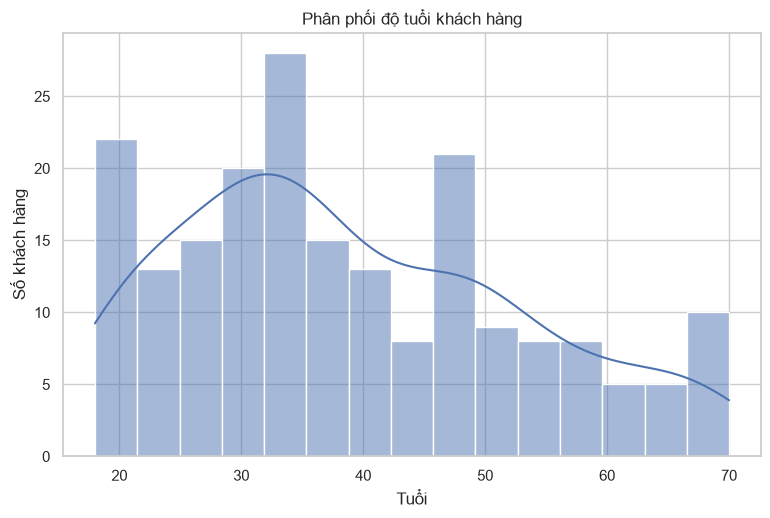

In [5]:
fig, ax = plt.subplots()
sns.histplot(data=raw_df, x="Age", bins=15, kde=True, ax=ax)
ax.set(title="Phân phối độ tuổi khách hàng", xlabel="Tuổi", ylabel="Số khách hàng")
save_figure(fig, "01_age_distribution.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – phân phối tuổi:** histogram cho biết tần suất theo tuổi; KDE chỉ làm mượt để quan sát hình dạng. Biểu đồ mô tả mẫu, không chứng minh tuổi gây ra mức chi tiêu cụ thể.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\02_age_boxplot.png


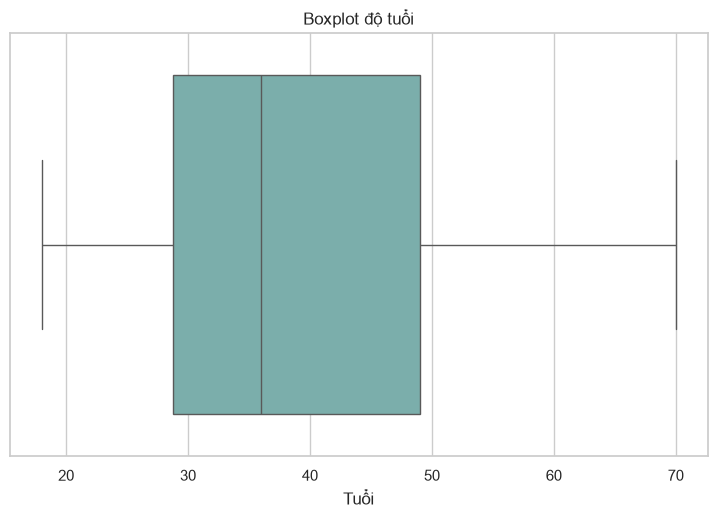

In [6]:
fig, ax = plt.subplots()
sns.boxplot(data=raw_df, x="Age", ax=ax, color="#72B7B2")
ax.set(title="Boxplot độ tuổi", xlabel="Tuổi")
save_figure(fig, "02_age_boxplot.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – boxplot tuổi:** điểm ngoài râu là quan sát cần kiểm tra theo quy tắc IQR, không đồng nghĩa dữ liệu sai và không phải lý do tự động loại khách hàng.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\03_income_distribution.png


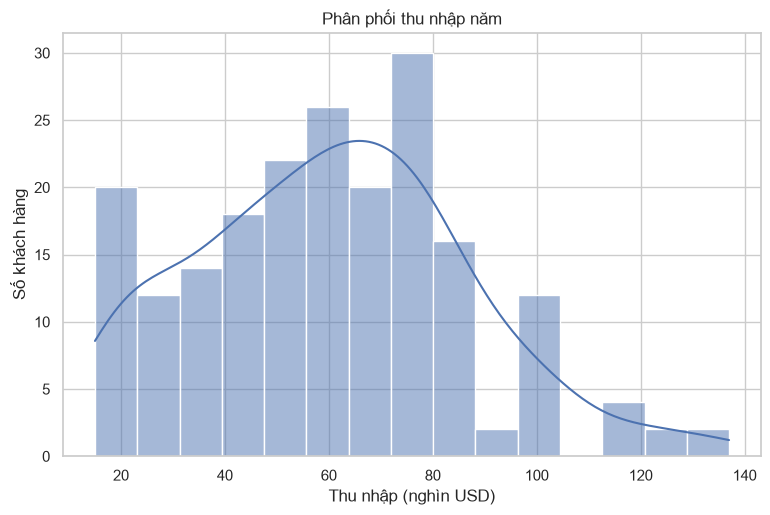

In [7]:
fig, ax = plt.subplots()
sns.histplot(data=raw_df, x="Annual Income (k$)", bins=15, kde=True, ax=ax)
ax.set(title="Phân phối thu nhập năm", xlabel="Thu nhập (nghìn USD)", ylabel="Số khách hàng")
save_figure(fig, "03_income_distribution.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – phân phối thu nhập:** histogram cho biết mật độ thu nhập trong mẫu. Giá trị lớn có thể ảnh hưởng khoảng cách Euclid của K-Means, vì vậy cần xem cùng boxplot và bước scaling.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\04_income_boxplot.png

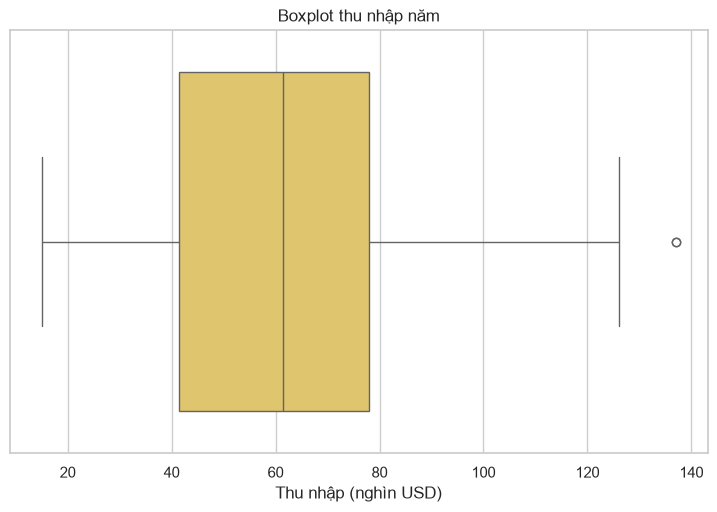

In [8]:
fig, ax = plt.subplots()
sns.boxplot(data=raw_df, x="Annual Income (k$)", ax=ax, color="#F2CF5B")
ax.set(title="Boxplot thu nhập năm", xlabel="Thu nhập (nghìn USD)")
save_figure(fig, "04_income_boxplot.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – boxplot thu nhập:** hình cho thấy độ phân tán và các giá trị ngoài ngưỡng IQR. Việc giữ hay loại quan sát cần căn cứ nghiệp vụ; notebook hiện giữ dữ liệu gốc.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\05_spending_distribution.png


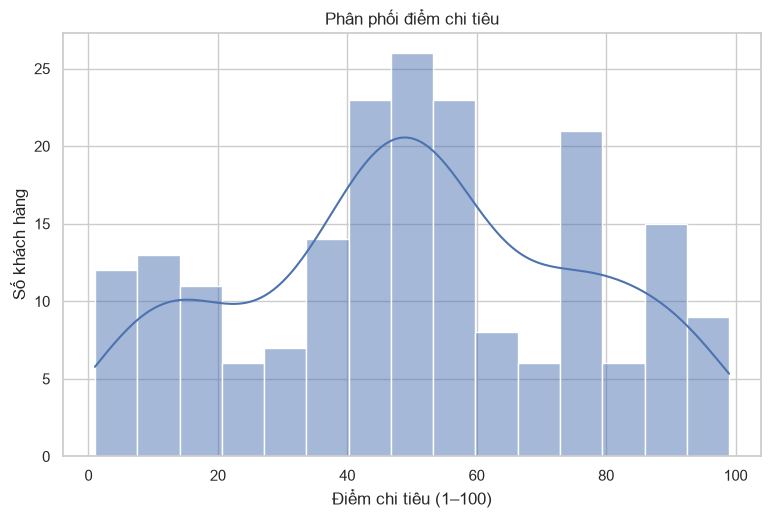

In [9]:
fig, ax = plt.subplots()
sns.histplot(data=raw_df, x="Spending Score (1-100)", bins=15, kde=True, ax=ax)
ax.set(title="Phân phối điểm chi tiêu", xlabel="Điểm chi tiêu (1–100)", ylabel="Số khách hàng")
save_figure(fig, "05_spending_distribution.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – phân phối điểm chi tiêu:** biểu đồ mô tả phân bố của thang điểm 1–100. Hình dạng phân phối không tự quyết định số cụm.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\06_spending_boxplot.png


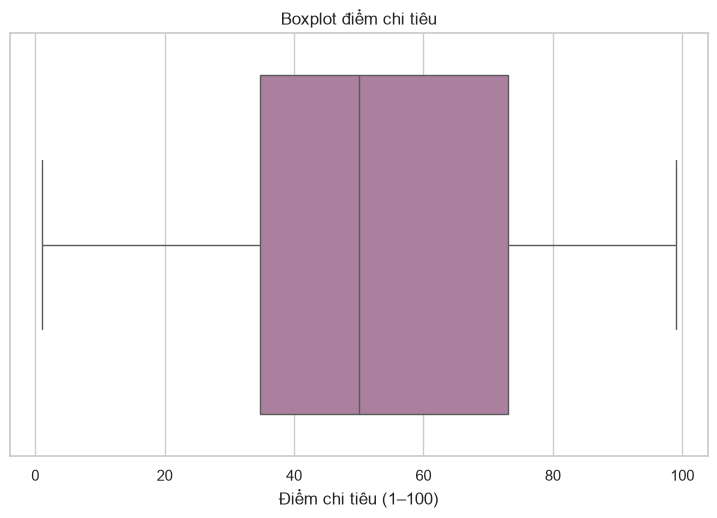

In [10]:
fig, ax = plt.subplots()
sns.boxplot(data=raw_df, x="Spending Score (1-100)", ax=ax, color="#B279A2")
ax.set(title="Boxplot điểm chi tiêu", xlabel="Điểm chi tiêu (1–100)")
save_figure(fig, "06_spending_boxplot.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – boxplot điểm chi tiêu:** điểm ngoài râu là giá trị xa phần giữa phân phối theo IQR; cần phân biệt quan sát hiếm với lỗi ghi nhận.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\07_gender_distribution.png


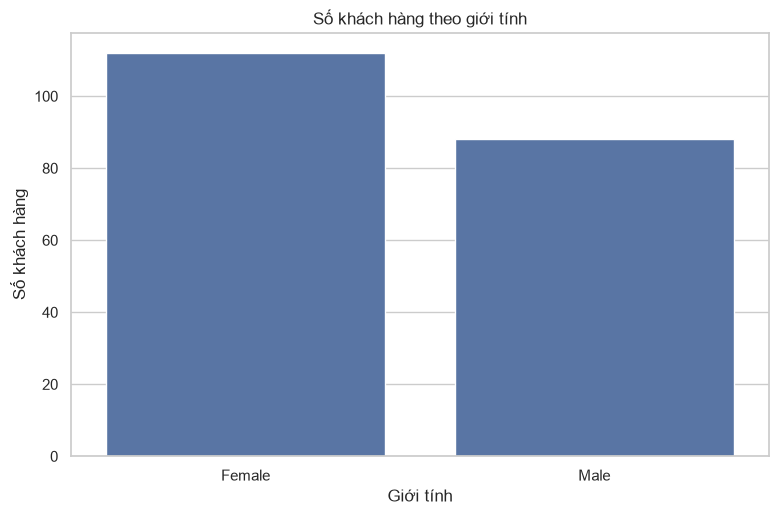

In [11]:
fig, ax = plt.subplots()
sns.countplot(data=raw_df, x="Gender", order=raw_df["Gender"].value_counts().index, ax=ax)
ax.set(title="Số khách hàng theo giới tính", xlabel="Giới tính", ylabel="Số khách hàng")
save_figure(fig, "07_gender_distribution.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – giới tính:** biểu đồ kiểm tra cơ cấu mẫu. Giới tính chỉ được mô tả và dùng ở cấu hình so sánh; mô hình hành vi chính không đưa biến này vào khoảng cách.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\08_correlation_heatmap.png


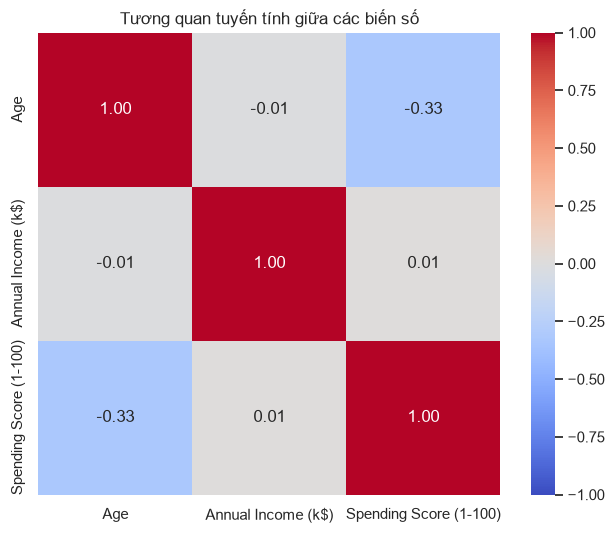

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000000,-0.012398,-0.327227
Annual Income (k$),-0.012398,1.000000,0.009903
Spending Score (1-100),-0.327227,0.009903,1.000000


In [12]:
correlation = raw_df[numeric_columns].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    correlation, annot=True, cmap="coolwarm", fmt=".2f",
    vmin=-1, vmax=1, center=0, square=True, ax=ax,
)
ax.set_title("Tương quan tuyến tính giữa các biến số")
save_figure(fig, "08_correlation_heatmap.png")
plt.show()
plt.close(fig)
display(correlation)

**Nhận xét và đánh giá – heatmap:** hệ số Pearson đo quan hệ tuyến tính từng cặp, không đo quan hệ nhân quả và không thể hiện đầy đủ cấu trúc đa biến mà phân cụm tìm kiếm.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\09_income_spending_scatter.png


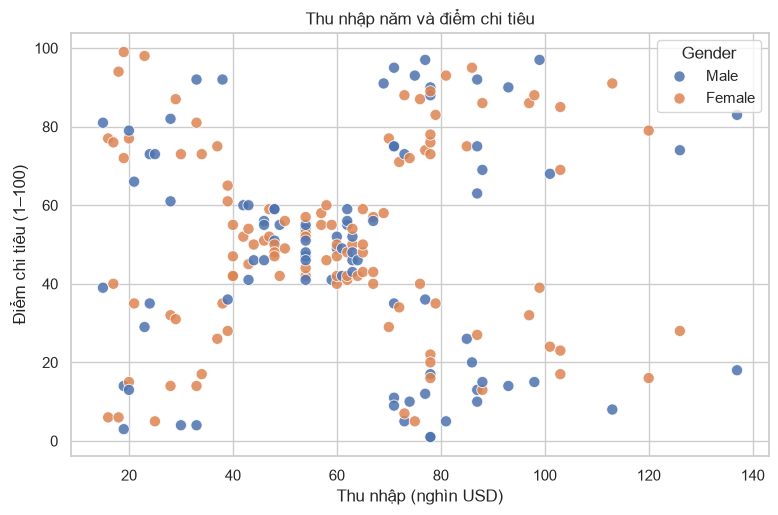

In [13]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=raw_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=65,
    alpha=0.85,
    ax=ax,
)
ax.set(
    title="Thu nhập năm và điểm chi tiêu",
    xlabel="Thu nhập (nghìn USD)",
    ylabel="Điểm chi tiêu (1–100)",
)
save_figure(fig, "09_income_spending_scatter.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – scatter thu nhập/chi tiêu:** mỗi điểm là một khách hàng; màu phân biệt giới tính. Biểu đồ chiếu hai biến nên chỉ gợi ý vùng tập trung, không xác nhận cụm trong không gian nhiều chiều.

## 3. Tiền xử lý và Feature Scaling

Feature, thứ tự cột, chính sách làm sạch và mã hóa được lấy từ cấu hình và hàm dùng chung với train/predict. CustomerID và Gender không tham gia mô hình chính.

In [14]:
FINAL_CONFIG = get_config("final_model")
FEATURE_SPACE = FINAL_CONFIG["feature_space"]
FEATURE_COLUMNS = get_config("experiments", "feature_spaces", FEATURE_SPACE)
GENDER_MAPPING = get_config("preprocessing", "encoding", "mapping")
SCALER_CLASSES = {
    "StandardScaler": StandardScaler,
    "MinMaxScaler": MinMaxScaler,
}

model_df = clean_records(raw_df)
X_df = prepare_feature_frame(model_df, FEATURE_COLUMNS, GENDER_MAPPING)
SCALER_NAME = FINAL_CONFIG["scaler"]
scaler = SCALER_CLASSES[SCALER_NAME]()
X_scaled = scaler.fit_transform(X_df)

print("Feature space:", FEATURE_SPACE)
print("Features theo đúng thứ tự:", FEATURE_COLUMNS)
print("Scaler:", SCALER_NAME)
print("Số bản ghi sau tiền xử lý:", len(X_scaled))
display(pd.DataFrame(X_scaled, columns=FEATURE_COLUMNS).head())

Feature space: without_gender
Features theo đúng thứ tự: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Scaler: StandardScaler
Số bản ghi sau tiền xử lý: 200


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


**Đánh giá tiền xử lý:** StandardScaler đưa các feature về cùng thang độ lệch chuẩn để biến có đơn vị lớn không lấn át khoảng cách. Khi dự đoán khách mới, notebook dùng lại scaler đã fit này.

## 4. Chọn K và đánh giá

Thử K theo khoảng cấu hình dự án (2–10). Silhouette cao hơn thường tốt hơn; Davies–Bouldin thấp hơn thường tốt hơn; Calinski–Harabasz cao hơn thường tốt hơn. Chỉ so sánh các K trong cùng feature space và scaler.

In [15]:
K_VALUES = get_config("experiments", "k_values")
MAX_ITER = int(FINAL_CONFIG["max_iterations"])
TOLERANCE = float(FINAL_CONFIG["tolerance"])
RANDOM_STATE = int(FINAL_CONFIG["random_state"])
INITIALIZATION = FINAL_CONFIG["initialization"]

metric_rows = []
for k in K_VALUES:
    candidate = KMeans(
        n_clusters=int(k),
        max_iter=MAX_ITER,
        tol=TOLERANCE,
        random_state=RANDOM_STATE,
        init=INITIALIZATION,
    )
    labels = candidate.fit_predict(X_scaled)
    metric_rows.append({
        "K": int(k),
        "Inertia": candidate.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies_Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Iterations": candidate.n_iter_,
    })

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(RESULT_DIR / "k_metrics.csv", index=False)
display(metrics_df.round(4))

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Iterations
0,2,389.3862,0.3355,1.2607,107.0956,7
1,3,295.5020,0.3590,1.0306,101.4987,6
2,4,205.2251,0.4040,0.9308,125.6764,7
3,5,168.2476,0.4166,0.8746,125.1009,8
4,6,134.3528,0.4311,0.8350,134.4752,6
5,7,124.4739,0.4139,0.9110,122.8859,5
6,8,113.7714,0.3890,0.9406,117.2224,6
7,9,102.2127,0.3924,0.9179,116.2739,6
8,10,91.2380,0.3755,0.9699,117.7199,6


Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\10_elbow.png


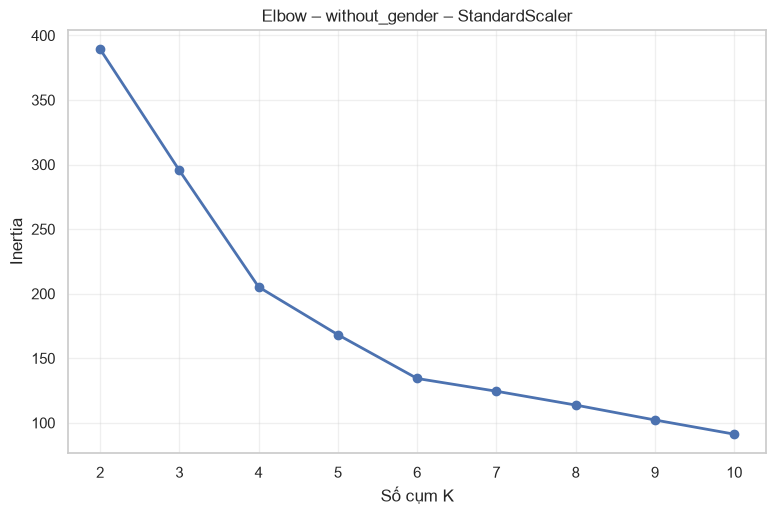

In [16]:
fig, ax = plt.subplots()
ax.plot(metrics_df["K"], metrics_df["Inertia"], marker="o", linewidth=2)
ax.set(title=f"Elbow – {FEATURE_SPACE} – {SCALER_NAME}", xlabel="Số cụm K", ylabel="Inertia")
ax.set_xticks(K_VALUES)
ax.grid(True, alpha=0.3)
save_figure(fig, "10_elbow.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – Elbow:** inertia luôn giảm khi K tăng; vị trí giảm bắt đầu dịu chỉ là heuristic. Cần đối chiếu đường cong với các metric và khả năng diễn giải cụm.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\11_silhouette_by_k.png


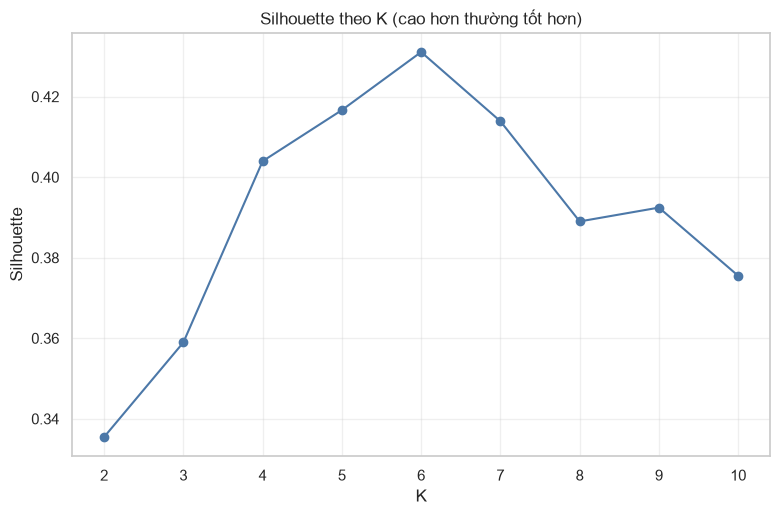

In [17]:
fig, ax = plt.subplots()
ax.plot(metrics_df["K"], metrics_df["Silhouette"], marker="o", color="#4C78A8")
ax.set(title="Silhouette theo K (cao hơn thường tốt hơn)", xlabel="K", ylabel="Silhouette")
ax.set_xticks(K_VALUES)
ax.grid(True, alpha=0.3)
save_figure(fig, "11_silhouette_by_k.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – Silhouette:** điểm gần 1 thường biểu thị cụm tách/gắn kết tốt hơn; gần 0 là vùng chồng lấn, âm có thể gợi ý gán cụm chưa phù hợp. Đây là metric nội bộ, không đo giá trị kinh doanh.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\12_davies_bouldin_by_k.png


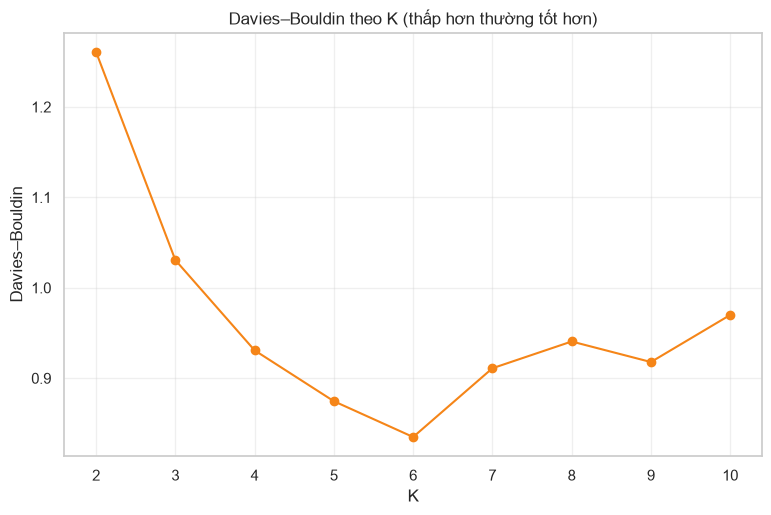

In [18]:
fig, ax = plt.subplots()
ax.plot(metrics_df["K"], metrics_df["Davies_Bouldin"], marker="o", color="#F58518")
ax.set(title="Davies–Bouldin theo K (thấp hơn thường tốt hơn)", xlabel="K", ylabel="Davies–Bouldin")
ax.set_xticks(K_VALUES)
ax.grid(True, alpha=0.3)
save_figure(fig, "12_davies_bouldin_by_k.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – Davies–Bouldin:** giá trị thấp hơn biểu thị cụm gọn/tách hơn theo định nghĩa metric; kết quả còn phụ thuộc feature, scaler và hình dạng cụm.

Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\13_calinski_harabasz_by_k.png


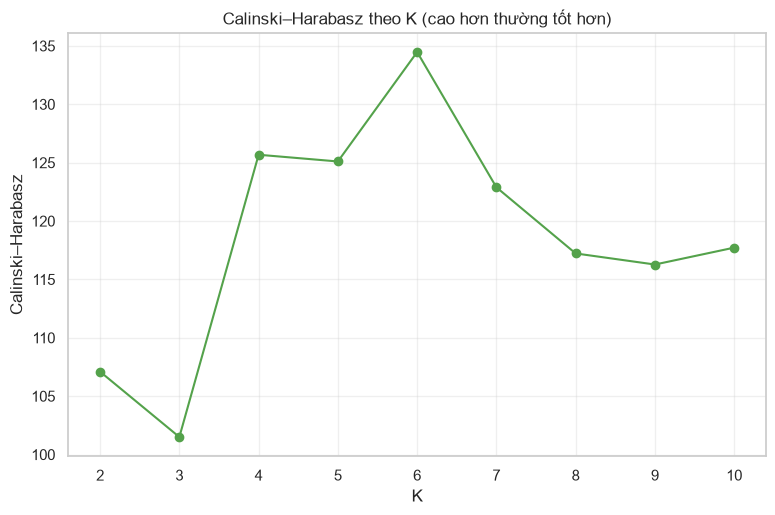

In [19]:
fig, ax = plt.subplots()
ax.plot(metrics_df["K"], metrics_df["Calinski_Harabasz"], marker="o", color="#54A24B")
ax.set(title="Calinski–Harabasz theo K (cao hơn thường tốt hơn)", xlabel="K", ylabel="Calinski–Harabasz")
ax.set_xticks(K_VALUES)
ax.grid(True, alpha=0.3)
save_figure(fig, "13_calinski_harabasz_by_k.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – Calinski–Harabasz:** điểm cao hơn thể hiện tỷ lệ phân tán giữa cụm so với trong cụm cao hơn; metric này không thay thế việc đọc hồ sơ cụm.

In [20]:
selected_k = int(FINAL_CONFIG["n_clusters"])
selected_metrics = metrics_df.loc[metrics_df["K"] == selected_k].iloc[0]
best_by_metric = pd.DataFrame({
    "Metric": ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz"],
    "Best K in tested range": [
        int(metrics_df.loc[metrics_df["Silhouette"].idxmax(), "K"]),
        int(metrics_df.loc[metrics_df["Davies_Bouldin"].idxmin(), "K"]),
        int(metrics_df.loc[metrics_df["Calinski_Harabasz"].idxmax(), "K"]),
    ],
})
print(f"K mô hình cuối theo config.yaml: {selected_k}")
display(selected_metrics.to_frame("Value").round(4))
print("K tốt nhất theo từng metric trong cùng feature space/scaler:")
display(best_by_metric)

K mô hình cuối theo config.yaml: 6


,Value
K,6.0000
Inertia,134.3528
Silhouette,0.4311
Davies_Bouldin,0.8350
Calinski_Harabasz,134.4752
Iterations,6.0000


K tốt nhất theo từng metric trong cùng feature space/scaler:


,Metric,Best K in tested range
0,Silhouette,6
1,Davies_Bouldin,6
2,Calinski_Harabasz,6


**Cơ sở chọn K cuối:** K lấy từ cấu hình mô hình cuối, sau đó được đối chiếu với Elbow, ba metric trên cùng dữ liệu đã scale, kích thước và hồ sơ cụm. Nếu metric không đồng thuận, cần nêu trade-off; không chọn chỉ để tối đa hóa một điểm số.

## 5. Huấn luyện và phân tích hồ sơ cụm

Nhãn cụm là mã kỹ thuật. Diễn giải dựa trên quy mô và trung bình tuổi/thu nhập/điểm chi tiêu; không gán nhãn tốt/xấu cho khách hàng.

In [21]:
final_model = KMeans(
    n_clusters=selected_k,
    max_iter=MAX_ITER,
    tol=TOLERANCE,
    random_state=RANDOM_STATE,
    init=INITIALIZATION,
)
final_labels = final_model.fit_predict(X_scaled)

clustered_df = model_df.copy()
clustered_df["Cluster"] = final_labels
cluster_profile = clustered_df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean"),
).round(2)
cluster_profile["Share_%"] = (
    100 * cluster_profile["Customers"] / len(clustered_df)
).round(2)

print("Inertia:", round(final_model.inertia_, 4))
print("Số vòng lặp:", final_model.n_iter_)
display(cluster_profile)
gender_profile = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["Gender"],
    normalize="index",
).mul(100).round(1)
print("Tỷ lệ giới tính để mô tả, không dùng để fit model (%):")
display(gender_profile)
clustered_df.to_csv(RESULT_DIR / "final_model_customer_clusters.csv", index=False)
cluster_profile.to_csv(RESULT_DIR / "final_model_cluster_profile.csv")

Inertia: 134.3528
Số vòng lặp: 6


,Customers,Average_Age,Average_Income,Average_Spending,Share_%
Cluster,,,,,
0,25,25.56,26.48,76.24,12.5
1,45,56.33,54.27,49.07,22.5
2,39,32.69,86.54,82.13,19.5
3,40,26.12,59.42,44.45,20.0
4,21,45.52,26.29,19.38,10.5
5,30,44.00,90.13,17.93,15.0


Tỷ lệ giới tính để mô tả, không dùng để fit model (%):


Gender,Female,Male
Cluster,,
0,56.0,44.0
1,57.8,42.2
2,53.8,46.2
3,60.0,40.0
4,61.9,38.1
5,46.7,53.3


Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\14_final_clusters_income_spending.png


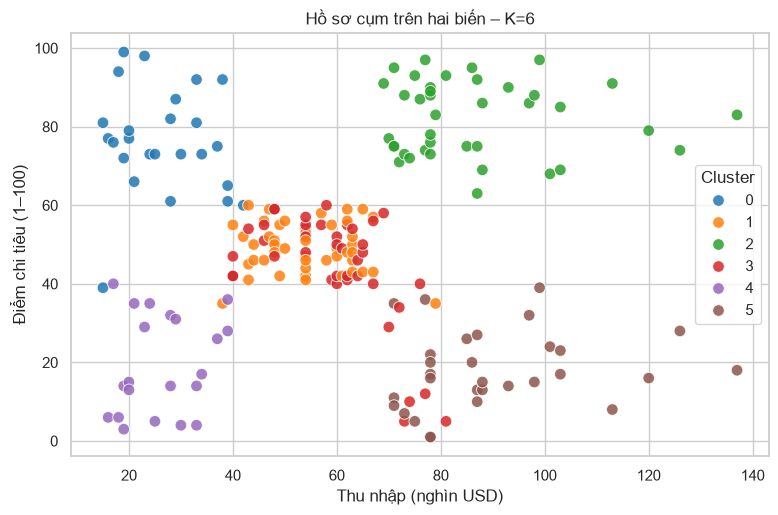

In [22]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=clustered_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=70,
    alpha=0.85,
    ax=ax,
)
ax.set(
    title=f"Hồ sơ cụm trên hai biến – K={selected_k}",
    xlabel="Thu nhập (nghìn USD)",
    ylabel="Điểm chi tiêu (1–100)",
)
save_figure(fig, "14_final_clusters_income_spending.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – biểu đồ cụm:** hình chiếu lên thu nhập và điểm chi tiêu; tuổi vẫn tham gia vào khoảng cách nhưng không hiện trên trục. Màu/mã cụm không biểu thị thứ hạng; cần đọc cùng bảng hồ sơ.

## 6. Dự đoán khách hàng mới

Ví dụ dùng cùng thứ tự feature, hàm chuẩn bị dữ liệu và scaler đã fit. Thay giá trị minh họa bằng dữ liệu khách hàng thực khi sử dụng.

In [23]:
new_customer = pd.DataFrame([{
    "Age": 25,
    "Annual Income (k$)": 60,
    "Spending Score (1-100)": 65,
}])
new_customer_features = prepare_feature_frame(
    new_customer, FEATURE_COLUMNS, GENDER_MAPPING
)
new_customer_scaled = scaler.transform(new_customer_features)
predicted_cluster = int(final_model.predict(new_customer_scaled)[0])
display(new_customer)
print("Cụm dự đoán:", predicted_cluster)

,Age,Annual Income (k$),Spending Score (1-100)
0,25,60,65


Cụm dự đoán: 3


**Đánh giá dự đoán:** đây là ví dụ minh họa trong cùng feature space; nhãn chỉ có ý nghĩa khi đối chiếu hồ sơ cụm và đúng phiên bản model/scaler.

## 7. Cấu hình so sánh được giữ từ notebook phân cụm cũ

Chạy riêng cấu hình có giới tính + MinMaxScaler + K=2 để giữ thí nghiệm ban đầu. Đây không phải mô hình chính. Vì feature space và scaler khác, không so sánh trực tiếp metric của nó với mô hình chính.

In [24]:
COMPARISON_CONFIG = get_config("comparison_analysis")
comparison_feature_space = COMPARISON_CONFIG["feature_space"]
comparison_columns = get_config(
    "experiments", "feature_spaces", comparison_feature_space
)
comparison_df_raw = clean_records(raw_df)
comparison_features = prepare_feature_frame(
    comparison_df_raw, comparison_columns, GENDER_MAPPING
)
comparison_scaler = SCALER_CLASSES[COMPARISON_CONFIG["scaler"]]()
comparison_X = comparison_scaler.fit_transform(comparison_features)
comparison_k = int(COMPARISON_CONFIG["n_clusters"])

comparison_model = KMeans(
    n_clusters=comparison_k,
    max_iter=int(COMPARISON_CONFIG["max_iterations"]),
    tol=float(COMPARISON_CONFIG["tolerance"]),
    random_state=int(COMPARISON_CONFIG["random_state"]),
    init=COMPARISON_CONFIG["initialization"],
)
comparison_labels = comparison_model.fit_predict(comparison_X)
comparison_df = comparison_df_raw.copy()
comparison_df["Cluster"] = comparison_labels
comparison_metrics = pd.DataFrame([{
    "Feature space": comparison_feature_space,
    "Scaler": COMPARISON_CONFIG["scaler"],
    "K": comparison_k,
    "Silhouette": silhouette_score(comparison_X, comparison_labels),
    "Davies_Bouldin": davies_bouldin_score(comparison_X, comparison_labels),
    "Calinski_Harabasz": calinski_harabasz_score(comparison_X, comparison_labels),
    "Inertia": comparison_model.inertia_,
}]).round(4)
display(comparison_metrics)

,Feature space,Scaler,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Inertia
0,with_gender,MinMaxScaler,2,0.5195,0.8173,262.4746,37.2723


In [25]:
comparison_profile = comparison_df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean"),
).round(2)
comparison_profile["Share_%"] = (
    100 * comparison_profile["Customers"] / len(comparison_df)
).round(2)
comparison_gender = pd.crosstab(
    comparison_df["Cluster"],
    comparison_df["Gender"],
    normalize="index",
).mul(100).round(1)

display(comparison_profile)
print("Tỷ lệ giới tính theo cụm (%):")
display(comparison_gender)
comparison_df.to_csv(RESULT_DIR / "comparison_customer_clusters.csv", index=False)
comparison_profile.to_csv(RESULT_DIR / "comparison_cluster_profile.csv")
print("Đầu ra notebook lưu riêng trong:", RESULT_DIR.relative_to(PROJECT_ROOT))

,Customers,Average_Age,Average_Income,Average_Spending,Share_%
Cluster,,,,,
0,88,39.81,62.23,48.51,44.0
1,112,38.10,59.25,51.53,56.0


Tỷ lệ giới tính theo cụm (%):


Gender,Female,Male
Cluster,,
0,0.0,100.0
1,100.0,0.0


Đầu ra notebook lưu riêng trong: notebooks\progress_results\unified_notebook


Đã lưu biểu đồ riêng: notebooks\reports\figures\customer_segmentation\unified\15_comparison_clusters_income_spending.png


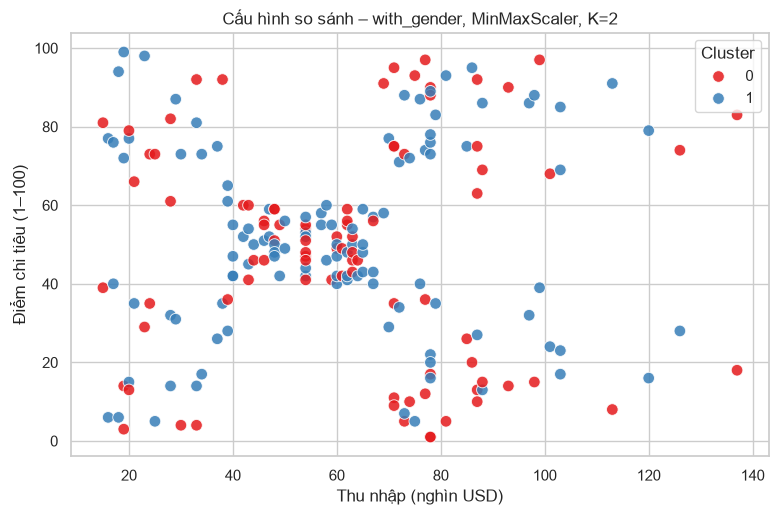

In [26]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=comparison_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=70,
    alpha=0.85,
    ax=ax,
)
ax.set(
    title=f"Cấu hình so sánh – {comparison_feature_space}, {COMPARISON_CONFIG['scaler']}, K={comparison_k}",
    xlabel="Thu nhập (nghìn USD)",
    ylabel="Điểm chi tiêu (1–100)",
)
save_figure(fig, "15_comparison_clusters_income_spending.png")
plt.show()
plt.close(fig)

**Nhận xét và đánh giá – biểu đồ cấu hình so sánh:** đây là phân cụm trong một không gian khác, có Gender và MinMaxScaler. Hình chỉ mô tả cấu hình đó, không thay thế hay xếp hạng mô hình chính.

## 8. Kết luận và giới hạn

- EDA, tiền xử lý, scaling, tìm K, đánh giá, phân tích cụm và dự đoán được trình bày liên tục trong một notebook.
- Mô hình chính dùng cùng feature/scaler với cấu hình huấn luyện và dự đoán; CustomerID và Gender không tham gia khoảng cách.
- Các biểu đồ được lưu thành file độc lập trong notebooks/reports/figures/customer_segmentation/unified/; mỗi hình có nhận xét/đánh giá riêng.
- Dữ liệu có 200 quan sát, không có nhãn chuẩn hay giao dịch thực tế. Đây là phân khúc khám phá; cần kiểm tra ổn định qua nhiều lần khởi tạo và xác thực với nghiệp vụ trước khi dùng cho quyết định marketing.